# FarmTech Solutions — Entrega 2: YOLO customizada × YOLO tradicional × CNN do zero

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fiapequipe7/FarmTech_Fase6/blob/main/entrega2/Equipe7_pbl_fase6.ipynb)

Projeto acadêmico da FIAP — PBL Fase 6, Entrega 2 · Equipe 7

## Objetivo

Na Entrega 1, treinamos um YOLOv5s para detectar **tomates** e **cenouras**. Nesta entrega, comparamos esse
modelo com outras duas abordagens, usando a mesma base de 80 imagens e as mesmas oito imagens de teste:

| Abordagem | O que é | Treino nesta base |
| --- | --- | --- |
| **A. YOLO customizada** | YOLOv5s ajustado na Entrega 1 (`best.pt`, 60 épocas) | Sim, na Entrega 1 |
| **B. YOLO tradicional** | YOLOv5s com os pesos padrão do COCO (80 classes) | Não |
| **C. CNN do zero** | Rede convolucional própria, com pesos iniciais aleatórios | Sim, nesta entrega |

As abordagens são avaliadas por **facilidade de uso/integração**, **precisão**, **tempo de
treinamento/customização** e **tempo de inferência**.

A YOLO tradicional usa os mesmos pesos que serviram de ponto de partida para o treino da Entrega 1.
Assim, a diferença entre A e B mostra o efeito da customização.

### Como executar

1. No Colab, selecione **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4**.
2. Mantenha a pasta `FarmTech_Fase6` da Entrega 1 em `Meu Drive`, com as subpastas `dataset` e `resultados`.
3. Execute **Ambiente de execução → Executar tudo** e autorize o acesso ao Google Drive.

## 1. Preparação do ambiente

Conectamos o Google Drive, definimos os caminhos e os parâmetros, instalamos o YOLOv5 na mesma versão
da Entrega 1 e configuramos o Keras.

In [1]:
import os
import sys
from pathlib import Path

# Identifica se o notebook está sendo executado no Google Colab.
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Conecta o Google Drive, onde estão o dataset e o modelo da Entrega 1.
    from google.colab import drive

    drive.mount("/content/drive")
    project_path = Path("/content/drive/MyDrive/FarmTech_Fase6")
    yolo_path = Path("/content/yolov5")
else:
    # Fora do Colab, os caminhos podem ser informados por variáveis de ambiente.
    project_path = Path(os.environ.get("FARMTECH_PROJECT_PATH", "FarmTech_Fase6")).resolve()
    yolo_path = Path(os.environ.get("YOLOV5_PATH", Path.home() / "yolov5")).resolve()

# Define as pastas de entrada desta entrega.
dataset_path = project_path / "dataset"
best_pt_path = project_path / "resultados" / "treino_60_epocas" / "weights" / "best.pt"

# Confere se os arquivos da Entrega 1 estão disponíveis.
assert dataset_path.is_dir(), f"Pasta não encontrada: {dataset_path}"
assert best_pt_path.is_file(), f"Modelo da Entrega 1 não encontrado: {best_pt_path}"

# Salva os resultados no Drive; se a pasta for somente leitura, usa o disco do ambiente de execução.
output_path = project_path / "resultados" / "entrega2"
try:
    output_path.mkdir(parents=True, exist_ok=True)
    (output_path / ".teste_escrita").write_text("ok")
    (output_path / ".teste_escrita").unlink()
except OSError:
    output_path = Path("/content/resultados_entrega2" if IN_COLAB else "resultados_entrega2").resolve()
    output_path.mkdir(parents=True, exist_ok=True)
    print("Aviso: sem permissão de escrita no Drive; os resultados serão salvos no ambiente de execução.")

print("Projeto:", project_path)
print("Resultados desta entrega:", output_path)

Mounted at /content/drive
Projeto: /content/drive/MyDrive/FarmTech_Fase6
Resultados desta entrega: /content/drive/MyDrive/FarmTech_Fase6/resultados/entrega2


In [2]:
# Parâmetros gerais dos experimentos.
SEED = 42                        # Semente principal, a mesma da Entrega 1.
CLASSES = ["tomate", "cenoura"]  # Ordem das classes da Entrega 1: 0 = tomate e 1 = cenoura.
CONF_THRES = 0.25                # Confiança mínima das detecções, a mesma da Entrega 1.
IOU_NMS = 0.6                    # IoU do NMS, o mesmo da Entrega 1.
IOU_ACERTO = 0.5                 # IoU mínimo para considerar o objeto localizado.
IMG_YOLO = 640                   # Resolução de entrada das YOLOs.
IMG_CNN = 128                    # Resolução de entrada da CNN.
MAX_LADO = 1280                  # Maior lado das imagens mantidas em memória.
YOLOV5_COMMIT = "f9578796"       # Versão do YOLOv5 usada na Entrega 1.

# Tempos totais de treino registrados no notebook da Entrega 1 (Colab, GPU T4), em minutos.
TEMPO_TREINO_E1_MIN = {30: 40.47, 60: 74.27}

In [3]:
import subprocess

# Baixa o YOLOv5 somente se ele ainda não existir no ambiente.
if not (yolo_path / "hubconf.py").is_file():
    subprocess.run(
        ["git", "clone", "-q", "https://github.com/ultralytics/yolov5.git", str(yolo_path)],
        check=True,
    )

# Fixa a mesma versão do código utilizada na Entrega 1.
subprocess.run(["git", "-C", str(yolo_path), "checkout", "-q", YOLOV5_COMMIT], check=True)

# Instala as dependências do YOLOv5 e mostra o log apenas em caso de erro.
instalacao = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r", str(yolo_path / "requirements.txt")],
    capture_output=True,
    text=True,
)
if instalacao.returncode != 0:
    print(instalacao.stdout[-3000:], instalacao.stderr[-3000:])
    raise RuntimeError("Falha na instalação das dependências do YOLOv5.")

print("YOLOv5 pronto no commit", YOLOV5_COMMIT)

YOLOv5 pronto no commit f9578796


A CNN é escrita em **Keras** e executada com o **backend PyTorch**, o mesmo framework das YOLOs.
Na Entrega 1, o log do Colab mostrou que o TensorFlow não encontrou as bibliotecas CUDA
(`Could not find cuda drivers on your machine, GPU will not be used`), enquanto o PyTorch usou a GPU T4.

Com o backend PyTorch, as três abordagens rodam no mesmo dispositivo e com as mesmas bibliotecas de GPU.
Assim, a comparação de tempos fica justa.

In [4]:
# Define o PyTorch como backend do Keras; deve ocorrer antes da importação do Keras.
os.environ["KERAS_BACKEND"] = "torch"
# Silencia os logs do TensorFlow, que o Keras importa indiretamente ao salvar arquivos.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import time
import warnings
from io import BytesIO

import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image as ImagemNotebook
from IPython.display import display
from keras import layers
from matplotlib import patheffects
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

# O best.pt foi salvo no Colab com Python 3.13, em que o pathlib virou pacote (pathlib._local).
# Este apelido permite ler o arquivo também em versões anteriores do Python.
if sys.version_info < (3, 13):
    import pathlib

    sys.modules.setdefault("pathlib._local", pathlib)

# Oculta avisos de depreciação que não afetam os resultados.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Usa a GPU quando disponível. O YOLOv5 identifica a primeira GPU como "0".
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE_YOLO = "0" if DEVICE == "cuda" else "cpu"

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("Dispositivo:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

Python: 3.13.15
PyTorch: 2.11.0+cu130 | Keras: 3.13.2 | backend: torch
Dispositivo: Tesla T4


In [5]:
# Cores fixas por abordagem (validadas para daltonismo) e cores neutras dos gráficos.
CORES = {"YOLO customizada": "#2a78d6", "YOLO tradicional": "#eb6834", "CNN do zero": "#1baf7a"}
TINTA, TINTA_SECUNDARIA, NEUTRO = "#0b0b0b", "#52514e", "#898781"
GRADE, EIXO, SUPERFICIE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
CMAP_AZUL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

# Estilo discreto: fundo claro, grade fina e textos em tons neutros.
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EIXO,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelcolor": TINTA_SECUNDARIA,
    "xtick.color": TINTA_SECUNDARIA,
    "ytick.color": TINTA_SECUNDARIA,
    "text.color": TINTA,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "font.size": 10,
    "figure.dpi": 90,
})


def mostrar_foto(fig, nome_arquivo=None, qualidade=80):
    """Exibe figuras com fotos em JPEG, reduzindo o tamanho do notebook; opcionalmente salva no Drive."""
    buffer = BytesIO()
    fig.savefig(buffer, format="jpeg", dpi=72, bbox_inches="tight", pil_kwargs={"quality": qualidade})
    plt.close(fig)
    if nome_arquivo:
        (output_path / nome_arquivo).write_bytes(buffer.getvalue())
    display(ImagemNotebook(data=buffer.getvalue(), format="jpeg"))


def mostrar_grafico(fig, nome_arquivo=None):
    """Exibe gráficos em PNG; opcionalmente salva uma cópia no Drive."""
    if nome_arquivo:
        fig.savefig(output_path / nome_arquivo, dpi=110, bbox_inches="tight")
    plt.show()


def exibir(tabela, pct=(), dec=(), dec1=()):
    """Exibe tabelas com percentuais, casas decimais e valores lógicos padronizados."""
    formatos = {coluna: "{:.1%}" for coluna in pct}
    formatos.update({coluna: "{:.3f}" for coluna in dec})
    formatos.update({coluna: "{:.1f}" for coluna in dec1})
    for coluna in tabela.columns:
        if tabela[coluna].dtype == bool:
            formatos[coluna] = lambda valor: "sim" if valor else "não"
    display(tabela.style.format(formatos, na_rep="—").hide(axis="index"))

## 2. Base de dados

Usamos as mesmas 80 imagens e a mesma divisão da Entrega 1: 64 de treino, 8 de validação e 8 de teste,
com metade de cada classe em cada conjunto.

A classe de cada imagem vem da marcação YOLO gerada na Entrega 1, que tem um objeto por imagem.
Conferimos que essa classe coincide com o nome do arquivo.

As fotos originais têm dezenas de megapixels. Para economizar memória, elas são decodificadas uma única vez
e reduzidas para 1280 px no maior lado. Essa resolução continua acima da entrada das YOLOs (640 px) e da CNN
(128 px). A caixa marcada é convertida para os pixels da imagem reduzida.

In [6]:
# Extensões de imagem aceitas.
EXTENSOES = {".jpg", ".jpeg", ".png", ".webp"}


def carregar_imagem(caminho):
    """Lê a imagem, corrige a orientação EXIF e reduz o maior lado para MAX_LADO pixels."""
    with Image.open(caminho) as arquivo:
        tamanho_original = arquivo.size
        # Decodifica o JPEG já em escala reduzida, o que acelera a leitura das fotos grandes.
        arquivo.draft("RGB", (MAX_LADO, MAX_LADO))
        imagem = ImageOps.exif_transpose(arquivo).convert("RGB")
    imagem.thumbnail((MAX_LADO, MAX_LADO), Image.Resampling.LANCZOS)
    return np.asarray(imagem), tamanho_original


inicio = time.perf_counter()
registros = []

for split in ("train", "val", "test"):
    for caminho in sorted((dataset_path / "images" / split).iterdir()):
        if caminho.suffix.lower() not in EXTENSOES:
            continue

        # Lê a marcação YOLO da Entrega 1: classe, centro, largura e altura normalizados.
        rotulo = dataset_path / "labels" / split / f"{caminho.stem}.txt"
        linhas = rotulo.read_text(encoding="utf-8").splitlines()
        assert len(linhas) == 1, f"Esperado um objeto por imagem: {rotulo}"
        classe_id, xc, yc, largura_n, altura_n = linhas[0].split()
        classe = CLASSES[int(classe_id)]
        assert caminho.stem.startswith(classe), f"Classe divergente do nome do arquivo: {caminho.name}"

        # Carrega a imagem e converte a caixa marcada para pixels [x1, y1, x2, y2].
        imagem, (largura_orig, altura_orig) = carregar_imagem(caminho)
        altura, largura = imagem.shape[:2]
        xc, yc, largura_n, altura_n = map(float, (xc, yc, largura_n, altura_n))
        caixa = np.array([
            (xc - largura_n / 2) * largura,
            (yc - altura_n / 2) * altura,
            (xc + largura_n / 2) * largura,
            (yc + altura_n / 2) * altura,
        ])

        registros.append({
            "split": split,
            "arquivo": caminho.name,
            "classe": classe,
            "imagem": imagem,
            "caixa": caixa,
            "megapixels": largura_orig * altura_orig / 1e6,
        })

dados = pd.DataFrame(registros)
treino, validacao, teste = (
    dados[dados["split"] == split].reset_index(drop=True) for split in ("train", "val", "test")
)

# Confere as quantidades exigidas pelo enunciado: 32/4/4 imagens por classe.
contagem = pd.crosstab(dados["split"], dados["classe"]).loc[["train", "val", "test"], CLASSES]
assert contagem.to_numpy().tolist() == [[32, 32], [4, 4], [4, 4]], contagem

contagem["total"] = contagem.sum(axis=1)
display(contagem)
print(f"{len(dados)} imagens carregadas em {time.perf_counter() - inicio:.1f} s.")
print(
    f"Resolução original: de {dados['megapixels'].min():.1f} a {dados['megapixels'].max():.1f} MP "
    f"(mediana de {dados['megapixels'].median():.1f} MP)."
)

classe,tomate,cenoura,total
split,,,
train,32,32,64
val,4,4,8
test,4,4,8


80 imagens carregadas em 93.3 s.
Resolução original: de 5.8 a 45.4 MP (mediana de 19.9 MP).


## 3. Protocolo de avaliação

As três abordagens têm saídas diferentes: as YOLOs **detectam** objetos (caixa, classe e confiança),
enquanto a CNN **classifica** a imagem inteira. Por isso, usamos uma métrica comum e uma específica.

**Métrica comum: classificação da imagem**, aplicada às três abordagens nas 8 imagens de teste.

- **YOLOs:** a classe da imagem é a da detecção mais confiante, com confiança ≥ 0,25 (o mesmo limiar das
  visualizações da Entrega 1). Sem nenhuma detecção, a resposta é `nenhuma` e conta como erro.
- **CNN:** a classe da imagem é a de maior probabilidade.
- **Métricas:** acurácia com intervalo de confiança de 95% (Wilson), precisão, recall e F1 por classe,
  e matriz de confusão.
- **Cautela com o tamanho do teste:** cada imagem vale 12,5 pontos percentuais, e o intervalo de confiança
  mostra a incerteza que isso traz.

**Métrica específica: localização**, só para as YOLOs.

- O objeto conta como **localizado** se alguma detecção da classe correta tiver IoU ≥ 0,5 com a caixa marcada.
- A base tem **uma caixa por imagem**, mesmo quando a foto mostra vários objetos, como um maço de cenouras.
  Por isso, uma detecção em um objeto não marcado não conta como acerto nem como erro.
- A métrica oficial de detecção da YOLO customizada (mAP) foi calculada na Entrega 1 e é retomada na seção 4.

**Leitura das grades de imagens:**

- A **caixa branca tracejada** é a marcação manual.
- As **caixas coloridas** são as detecções com confiança ≥ 0,25; só as três mais confiantes de cada imagem
  recebem rótulo.
- O título de cada imagem traz a resposta do modelo e se ela está certa ou errada.

In [7]:
COLUNAS_CAIXA = ["xmin", "ymin", "xmax", "ymax"]
ROTULOS_MATRIZ = CLASSES + ["nenhuma"]


def iou(caixa_a, caixa_b):
    """Interseção sobre união (IoU) entre duas caixas no formato [x1, y1, x2, y2]."""
    largura = max(0.0, min(caixa_a[2], caixa_b[2]) - max(caixa_a[0], caixa_b[0]))
    altura = max(0.0, min(caixa_a[3], caixa_b[3]) - max(caixa_a[1], caixa_b[1]))
    intersecao = largura * altura
    area_a = (caixa_a[2] - caixa_a[0]) * (caixa_a[3] - caixa_a[1])
    area_b = (caixa_b[2] - caixa_b[0]) * (caixa_b[3] - caixa_b[1])
    return intersecao / (area_a + area_b - intersecao)


def intervalo_wilson(acertos, total, z=1.96):
    """Intervalo de confiança de 95% (Wilson) para uma proporção."""
    proporcao = acertos / total
    centro = (proporcao + z**2 / (2 * total)) / (1 + z**2 / total)
    margem = z * np.sqrt(proporcao * (1 - proporcao) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return centro - margem, centro + margem


def metricas_classificacao(y_real, y_previsto):
    """Acurácia com IC95% e precisão, recall e F1 por classe (a resposta 'nenhuma' conta como erro)."""
    y_real, y_previsto = np.asarray(y_real), np.asarray(y_previsto)
    acertos = int((y_real == y_previsto).sum())
    ic_inferior, ic_superior = intervalo_wilson(acertos, len(y_real))
    precisao, recall, f1, _ = precision_recall_fscore_support(
        y_real, y_previsto, labels=CLASSES, zero_division=0
    )
    resumo = {
        "acertos": f"{acertos}/{len(y_real)}",
        "acurácia": acertos / len(y_real),
        "IC95% inferior": ic_inferior,
        "IC95% superior": ic_superior,
        "F1 macro": f1.mean(),
    }
    for indice, classe in enumerate(CLASSES):
        resumo[f"precisão {classe}"] = precisao[indice]
        resumo[f"recall {classe}"] = recall[indice]
    return resumo


def exibir_metricas(tabela):
    """Mostra as métricas de classificação de uma tabela com as colunas 'real' e 'previsto'."""
    resumo = pd.DataFrame([metricas_classificacao(tabela["real"], tabela["previsto"])])
    exibir(resumo, pct=[coluna for coluna in resumo.columns if coluna != "acertos"])


def prever_yolo(modelo, imagens, lote=8):
    """Executa a YOLO em lotes e devolve uma tabela de detecções por imagem."""
    deteccoes = []
    for inicio_lote in range(0, len(imagens), lote):
        resultados = modelo(list(imagens[inicio_lote:inicio_lote + lote]), size=IMG_YOLO)
        deteccoes.extend(resultados.pandas().xyxy)
    return deteccoes


def deteccao_principal(deteccoes, mapeamento, conf):
    """Detecção mais confiante entre as classes do mapeamento, já convertida para a classe do projeto."""
    validas = deteccoes[(deteccoes["confidence"] >= conf) & deteccoes["name"].isin(list(mapeamento))]
    if validas.empty:
        return "nenhuma", np.nan, "—", None
    topo = validas.loc[validas["confidence"].idxmax()]
    return mapeamento[topo["name"]], topo["confidence"], topo["name"], topo[COLUNAS_CAIXA].to_numpy(float)


def resumir_yolo(itens, deteccoes, mapeamento, conf=CONF_THRES):
    """Tabela por imagem: classe prevista, confiança, IoU da detecção principal e localização."""
    linhas = []
    for item, deteccoes_imagem in zip(itens.itertuples(), deteccoes):
        prevista, confianca, nome_yolo, caixa = deteccao_principal(deteccoes_imagem, mapeamento, conf)

        # O objeto está localizado se alguma detecção da classe certa cobrir a caixa marcada.
        corretas = deteccoes_imagem[
            (deteccoes_imagem["confidence"] >= conf)
            & (deteccoes_imagem["name"].map(mapeamento) == item.classe)
        ]
        localizou = any(
            iou(caixa_prevista, item.caixa) >= IOU_ACERTO
            for caixa_prevista in corretas[COLUNAS_CAIXA].to_numpy(float)
        )

        linhas.append({
            "arquivo": item.arquivo,
            "real": item.classe,
            "previsto": prevista,
            "classe na YOLO": nome_yolo,
            "confiança": confianca,
            "IoU": iou(caixa, item.caixa) if caixa is not None else np.nan,
            "acertou a classe": prevista == item.classe,
            "localizou": localizou,
        })
    return pd.DataFrame(linhas)

In [8]:
def desenhar_caixa(eixo, caixa, cor, texto=None, tracejada=False):
    """Desenha uma caixa [x1, y1, x2, y2] com contorno escuro para destacá-la sobre a foto."""
    x1, y1, x2, y2 = caixa
    retangulo = Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor=cor, linewidth=2.2, linestyle="--" if tracejada else "-",
    )
    retangulo.set_path_effects([patheffects.withStroke(linewidth=4, foreground="black")])
    eixo.add_patch(retangulo)
    if texto:
        # Perto da borda superior, o rótulo vai para dentro da caixa para não sair da foto.
        dentro = y1 < 0.08 * eixo.get_images()[0].get_array().shape[0]
        eixo.text(
            x1, y1, texto, fontsize=8, color="white", va="top" if dentro else "bottom",
            bbox={"facecolor": "black", "alpha": 0.7, "pad": 1.5, "edgecolor": "none"},
        )


def mostrar_deteccoes(itens, deteccoes, tabela, cor, titulo, nome_arquivo, rotulos_por_imagem=3):
    """Grade com as imagens de teste: caixa marcada (branca tracejada) e detecções com confiança ≥ 0,25.

    Todas as detecções são desenhadas, mas só as mais confiantes recebem rótulo, para não poluir a imagem.
    """
    fig, eixos = plt.subplots(2, 4, figsize=(16, 8.4))
    for eixo, item, deteccoes_imagem, resumo in zip(
        eixos.flat, itens.itertuples(), deteccoes, tabela.itertuples()
    ):
        eixo.imshow(item.imagem)
        desenhar_caixa(eixo, item.caixa, "white", tracejada=True)
        # Desenha da menor para a maior confiança: a detecção principal fica por cima das demais.
        confiaveis = deteccoes_imagem[deteccoes_imagem["confidence"] >= CONF_THRES]
        confiaveis = confiaveis.sort_values("confidence").reset_index(drop=True)
        for posicao, deteccao in enumerate(confiaveis.itertuples()):
            rotular = posicao >= len(confiaveis) - rotulos_por_imagem
            desenhar_caixa(
                eixo,
                [deteccao.xmin, deteccao.ymin, deteccao.xmax, deteccao.ymax],
                cor,
                texto=f"{deteccao.name} {deteccao.confidence:.2f}" if rotular else None,
            )
        resultado = "certo" if resumo.previsto == resumo.real else "errado"
        eixo.set_title(f"{item.arquivo}\nprevisto: {resumo.previsto} ({resultado})", fontsize=10)
        eixo.axis("off")
    fig.suptitle(titulo, fontsize=13, fontweight="bold")
    fig.tight_layout()
    mostrar_foto(fig, nome_arquivo)

## 4. Abordagem A — YOLO customizada (Entrega 1)

O YOLOv5s foi ajustado na Entrega 1 com as 64 imagens de treino, rotuladas com polígonos no Make Sense IA
e convertidas em caixas. O modelo de 60 épocas foi escolhido pela validação.

| Métrica no teste (Entrega 1, `val.py`) | Tomate | Cenoura | Geral |
| --- | ---: | ---: | ---: |
| mAP@0.5 | 0,995 | 0,190 | 0,593 |
| mAP@0.5:0.95 | 0,548 | 0,057 | 0,302 |

O treino levou **74,27 minutos** (60 épocas, GPU T4), contra 40,47 minutos no experimento de 30 épocas.

Aqui, carregamos o `best.pt` pelo `torch.hub` e aplicamos o protocolo da seção 3. Para permitir a análise
de limiar, as detecções são geradas com confiança mínima de 0,001 e filtradas depois.

In [9]:
# Carrega o modelo da Entrega 1 com o carregador oficial do YOLOv5 (torch.hub, cópia local).
modelo_custom = torch.hub.load(
    str(yolo_path), "custom", path=str(best_pt_path), source="local", device=DEVICE_YOLO, _verbose=False
)
modelo_custom.conf, modelo_custom.iou = 0.001, IOU_NMS  # Limiar baixo: o filtro é aplicado depois.

# Mapeamento das classes do modelo para as classes do projeto (aqui, são as mesmas).
MAPA_CUSTOM = {classe: classe for classe in CLASSES}
print("Classes do modelo:", modelo_custom.names)

# Gera as detecções das 8 imagens de teste e resume pelo protocolo da seção 3.
deteccoes_custom = prever_yolo(modelo_custom, teste["imagem"].tolist())
tabela_custom = resumir_yolo(teste, deteccoes_custom, MAPA_CUSTOM)

exibir(tabela_custom, dec=["confiança", "IoU"])
exibir_metricas(tabela_custom)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Classes do modelo: {0: 'tomate', 1: 'cenoura'}


arquivo,real,previsto,classe na YOLO,confiança,IoU,acertou a classe,localizou
cenoura33.jpg,cenoura,nenhuma,—,—,—,não,não
cenoura34.jpg,cenoura,nenhuma,—,—,—,não,não
cenoura35.jpg,cenoura,nenhuma,—,—,—,não,não
cenoura36.jpg,cenoura,nenhuma,—,—,—,não,não
tomate1.jpg,tomate,tomate,tomate,0.627,0.843,sim,sim
tomate2.jpg,tomate,tomate,tomate,0.701,0.813,sim,sim
tomate3.jpg,tomate,tomate,tomate,0.517,0.728,sim,sim
tomate4.jpg,tomate,tomate,tomate,0.426,0.782,sim,sim


acertos,acurácia,IC95% inferior,IC95% superior,F1 macro,precisão tomate,recall tomate,precisão cenoura,recall cenoura
4/8,50.0%,21.5%,78.5%,50.0%,100.0%,100.0%,0.0%,0.0%


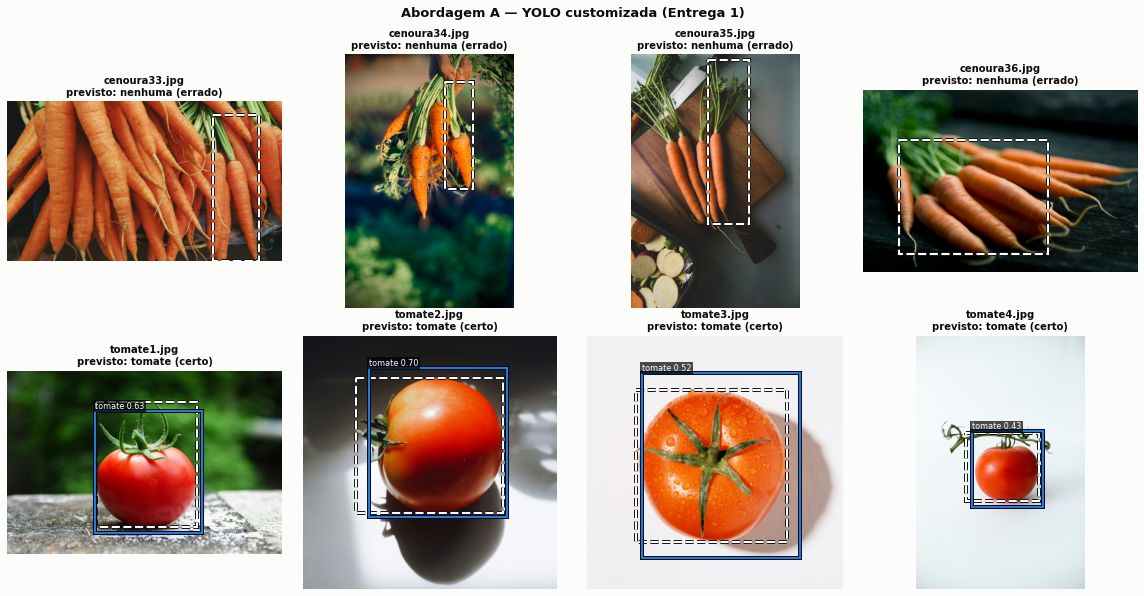

In [10]:
# Imagens de teste processadas pela YOLO customizada.
mostrar_deteccoes(
    teste, deteccoes_custom, tabela_custom, CORES["YOLO customizada"],
    "Abordagem A — YOLO customizada (Entrega 1)", "a_yolo_customizada_teste.jpg",
)

### Análise da abordagem A

- **Tomates: 4 de 4.**
  - As confianças ficaram entre 0,43 e 0,70.
  - As caixas coincidem bem com a marcação (IoU de 0,73 a 0,84).
  - É o mesmo comportamento observado na Entrega 1.
- **Cenouras: 0 de 4.** Com o limiar de 0,25, nenhuma cenoura é detectada, e a acurácia fica em 50%
  (IC95% de 22% a 78%).
- **Por que as cenouras falham?** As grades mostram uma causa na própria base:
  - Cada foto tem **uma única caixa marcada**, mas as fotos de cenoura mostram maços.
  - A caixa ora cobre uma cenoura, ora duas, ora o maço inteiro, quase sempre com as folhas.
  - No treino, as cenouras não marcadas contam como "fundo", e a rede recebe sinais contraditórios sobre
    o que é uma cenoura.
  - O resultado é uma **confiança baixa** nessa classe, abaixo de 0,25, e não a ausência de detecção.
    A seção 5.3 confirma isso.

## 5. Abordagem B — YOLO tradicional (COCO, sem re-treino)

A YOLO tradicional é o YOLOv5s distribuído com os pesos treinados no **COCO**, uma base com 80 classes
de uso geral. É o mesmo arquivo `yolov5s.pt` que serviu de ponto de partida para o treino da Entrega 1.

O COCO tem 10 classes de alimentos, entre elas `carrot` (cenoura), mas **não tem tomate**. A hipótese é
que o modelo reconheça cenouras sem nenhum treino, mas não consiga nomear os tomates corretamente.

In [11]:
# Baixa (se necessário) e carrega o YOLOv5s com os pesos padrão do COCO.
pesos_coco = yolo_path / "yolov5s.pt"
modelo_coco = torch.hub.load(
    str(yolo_path), "custom", path=str(pesos_coco), source="local", device=DEVICE_YOLO, _verbose=False
)
modelo_coco.conf, modelo_coco.iou = 0.001, IOU_NMS

# Classes de alimentos do COCO, as únicas consideradas na classificação da imagem.
ALIMENTOS_COCO = ["banana", "apple", "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake"]
assert set(ALIMENTOS_COCO) <= set(modelo_coco.names.values())

print(f"Total de classes do COCO: {len(modelo_coco.names)}")
print("Classes de alimentos:", ", ".join(ALIMENTOS_COCO))
print("Existe a classe 'tomato'?", "tomato" in modelo_coco.names.values())

Total de classes do COCO: 80
Classes de alimentos: banana, apple, sandwich, orange, broccoli, carrot, hot dog, pizza, donut, cake
Existe a classe 'tomato'? False


### 5.1 Adaptação sem re-treino: mapeamento de classes

O vocabulário do COCO é fechado. Para usá-lo no nosso problema sem re-treinar a rede, criamos uma
tabela de correspondência entre as classes do COCO e as nossas classes:

1. Aplicamos a YOLO tradicional às **64 imagens de treino** e registramos a classe de alimento mais
   confiante de cada uma.
2. Cada classe do COCO é associada à nossa classe em que aparece mais vezes (maioria de votos).
   Classes com só um voto são descartadas como ruído.

O teste não participa dessa etapa. O tempo gasto é o **tempo de customização** desta abordagem.

No teste, avaliamos dois modos:

- **Estrito:** usa só a correspondência nativa `carrot → cenoura`. Como não existe a classe tomate,
  nenhum tomate pode ser acertado.
- **Mapeado:** usa a tabela aprendida no treino. É o melhor cenário possível sem re-treino.

In [12]:
# Classifica as imagens de treino pela classe de alimento mais confiante (sem mapeamento ainda).
inicio = time.perf_counter()
deteccoes_treino_coco = prever_yolo(modelo_coco, treino["imagem"].tolist())
tabela_treino_coco = resumir_yolo(treino, deteccoes_treino_coco, {nome: nome for nome in ALIMENTOS_COCO})

# Conta as classes do COCO previstas para cada classe real (votos).
votos = pd.crosstab(tabela_treino_coco["real"], tabela_treino_coco["previsto"])

# Associa cada classe do COCO à classe real com mais votos.
# Classes com menos de 2 votos (ruído) e empates são descartados.
MIN_VOTOS = 2
MAPA_APRENDIDO = {}
for nome_coco in votos.columns.drop("nenhuma", errors="ignore"):
    contagens = votos[nome_coco].sort_values(ascending=False)
    if contagens.iloc[0] >= MIN_VOTOS and (len(contagens) == 1 or contagens.iloc[0] > contagens.iloc[1]):
        MAPA_APRENDIDO[nome_coco] = contagens.index[0]
tempo_mapeamento = time.perf_counter() - inicio

MAPA_ESTRITO = {"carrot": "cenoura"}

print("Classe de alimento mais confiante nas 64 imagens de treino (linhas = classe real):")
display(votos)
print("Mapeamento aprendido no treino:", MAPA_APRENDIDO)
print(f"Tempo de customização (inferência no treino + contagem): {tempo_mapeamento:.1f} s")

Classe de alimento mais confiante nas 64 imagens de treino (linhas = classe real):


previsto,apple,cake,carrot,donut,nenhuma,orange
real,,,,,,
cenoura,1,0,30,0,1,0
tomate,17,1,0,1,5,8


Mapeamento aprendido no treino: {'apple': 'tomate', 'carrot': 'cenoura', 'orange': 'tomate'}
Tempo de customização (inferência no treino + contagem): 1.1 s


### 5.2 Avaliação no teste

In [13]:
# Gera as detecções da YOLO tradicional nas 8 imagens de teste.
deteccoes_coco = prever_yolo(modelo_coco, teste["imagem"].tolist())

# Avalia os dois modos: só a correspondência nativa e o mapeamento aprendido no treino.
tabela_coco_estrito = resumir_yolo(teste, deteccoes_coco, MAPA_ESTRITO)
tabela_coco_mapa = resumir_yolo(teste, deteccoes_coco, MAPA_APRENDIDO)

print("Modo estrito (carrot → cenoura):")
exibir_metricas(tabela_coco_estrito)
print("Modo mapeado (tabela aprendida no treino):")
exibir(tabela_coco_mapa, dec=["confiança", "IoU"])
exibir_metricas(tabela_coco_mapa)

Modo estrito (carrot → cenoura):


acertos,acurácia,IC95% inferior,IC95% superior,F1 macro,precisão tomate,recall tomate,precisão cenoura,recall cenoura
4/8,50.0%,21.5%,78.5%,44.4%,0.0%,0.0%,80.0%,100.0%


Modo mapeado (tabela aprendida no treino):


arquivo,real,previsto,classe na YOLO,confiança,IoU,acertou a classe,localizou
cenoura33.jpg,cenoura,cenoura,carrot,0.795,0.000,sim,não
cenoura34.jpg,cenoura,cenoura,carrot,0.754,0.000,sim,não
cenoura35.jpg,cenoura,cenoura,carrot,0.775,0.000,sim,não
cenoura36.jpg,cenoura,cenoura,carrot,0.694,0.274,sim,não
tomate1.jpg,tomate,tomate,apple,0.705,0.643,sim,sim
tomate2.jpg,tomate,tomate,orange,0.567,0.840,sim,sim
tomate3.jpg,tomate,cenoura,carrot,0.327,0.188,não,não
tomate4.jpg,tomate,nenhuma,—,—,—,não,não


acertos,acurácia,IC95% inferior,IC95% superior,F1 macro,precisão tomate,recall tomate,precisão cenoura,recall cenoura
6/8,75.0%,40.9%,92.9%,77.8%,100.0%,50.0%,80.0%,100.0%


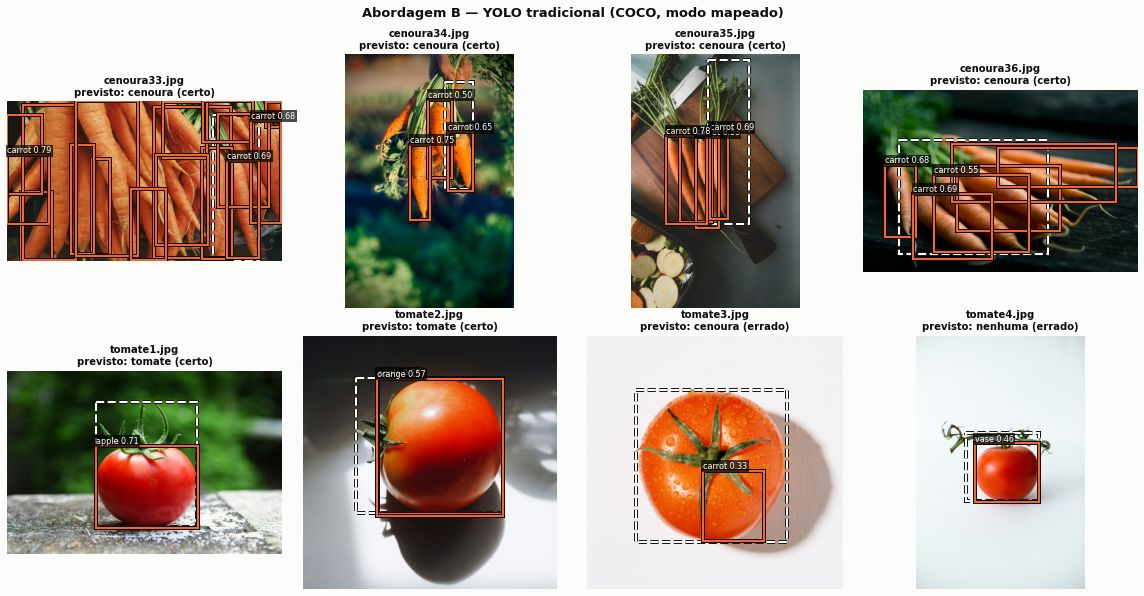

In [14]:
# Imagens de teste com todas as detecções da YOLO tradicional (todas as 80 classes, confiança ≥ 0,25).
mostrar_deteccoes(
    teste, deteccoes_coco, tabela_coco_mapa, CORES["YOLO tradicional"],
    "Abordagem B — YOLO tradicional (COCO, modo mapeado)", "b_yolo_tradicional_teste.jpg",
)

### 5.3 Limiar de confiança calibrado na validação (A × B)

O limiar de 0,25 foi herdado da Entrega 1 sem nenhum ajuste. Aqui verificamos se outro limiar seria
mais adequado para cada YOLO:

1. Testamos limiares de 0,05 a 0,50 nas 8 imagens de **validação**. O teste não é usado nessa escolha.
2. Escolhemos o limiar com a maior acurácia na validação. Em caso de empate, ficamos com o maior, que é
   mais conservador.
3. Aplicamos o limiar escolhido ao teste.

O resultado com 0,25 continua sendo o **oficial**. O resultado calibrado indica o potencial de cada modelo
quando o limiar é ajustado de forma legítima.

In [15]:
# Limiares avaliados na validação.
LIMIARES = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

yolos = {
    "A. YOLO customizada": (modelo_custom, MAPA_CUSTOM, deteccoes_custom),
    "B. YOLO tradicional (mapeada)": (modelo_coco, MAPA_APRENDIDO, deteccoes_coco),
}
acuracia_por_limiar, calibracao, calibrado = {}, [], {}

for nome, (modelo, mapeamento, deteccoes_teste) in yolos.items():
    # Detecções nas imagens de validação e acurácia para cada limiar.
    deteccoes_val = prever_yolo(modelo, validacao["imagem"].tolist())
    acuracias = {
        limiar: resumir_yolo(validacao, deteccoes_val, mapeamento, conf=limiar)["acertou a classe"].mean()
        for limiar in LIMIARES
    }
    acuracia_por_limiar[nome] = {f"{limiar:.2f}": valor for limiar, valor in acuracias.items()}

    # Maior limiar entre os de melhor acurácia na validação, aplicado ao teste.
    limiar = max(t for t, valor in acuracias.items() if valor == max(acuracias.values()))
    tabela_calibrada = resumir_yolo(teste, deteccoes_teste, mapeamento, conf=limiar)
    calibrado[nome] = (limiar, tabela_calibrada)
    calibracao.append({
        "abordagem": nome,
        "limiar escolhido": f"{limiar:.2f}",
        "acurácia validação": acuracias[limiar],
        "acurácia teste (0.25)": resumir_yolo(teste, deteccoes_teste, mapeamento)["acertou a classe"].mean(),
        "acurácia teste (calibrado)": tabela_calibrada["acertou a classe"].mean(),
        "localização teste (calibrado)": tabela_calibrada["localizou"].mean(),
    })

print("Acurácia na validação por limiar de confiança:")
display(pd.DataFrame(acuracia_por_limiar).T.style.format("{:.0%}"))
calibracao = pd.DataFrame(calibracao)
exibir(calibracao, pct=[coluna for coluna in calibracao.columns if coluna not in ("abordagem", "limiar escolhido")])

Acurácia na validação por limiar de confiança:


,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50
A. YOLO customizada,100%,100%,88%,62%,62%,50%,38%,38%,38%,25%
B. YOLO tradicional (mapeada),100%,100%,100%,100%,100%,88%,75%,75%,75%,75%


abordagem,limiar escolhido,acurácia validação,acurácia teste (0.25),acurácia teste (calibrado),localização teste (calibrado)
A. YOLO customizada,0.10,100.0%,50.0%,100.0%,87.5%
B. YOLO tradicional (mapeada),0.25,100.0%,75.0%,75.0%,25.0%


### Análise da abordagem B

- **Cenouras: 4 de 4 sem nenhum treino.**
  - O COCO já tem a classe `carrot`, e as confianças ficaram entre 0,69 e 0,80.
  - A YOLO tradicional é a única que marca cada cenoura do maço separadamente.
- **Tomates: o vocabulário fechado é o limite.**
  - Nas imagens de treino, a rede chamou os tomates de `apple` (17 vezes) e `orange` (8 vezes).
  - No modo estrito, erra todos os tomates (acurácia de 50%).
  - Com o mapeamento aprendido no treino, sobe para 75% (6 de 8).
  - Os erros são o `tomate3`, um tomate alaranjado cujo cabinho foi detectado como `carrot`, e o `tomate4`,
    um tomate pequeno sobre fundo branco detectado como `vase` (vaso).
- **Localização baixa (25%) não significa detecção ruim.**
  - A rede desenha uma caixa para cada cenoura, enquanto nossa marcação cobre um maço ou inclui as folhas.
    Por isso, detecções corretas têm IoU baixo com a caixa marcada, por uma simples diferença de convenção
    de rotulação.
  - Nos dois tomates que acertou, a caixa coincide com a marcação (IoU de 0,64 e 0,84).

**Limiar calibrado na validação**

- **YOLO customizada:** a validação escolhe o limiar 0,10. No teste, a acurácia sobe de 50% para **100%**
  (8 de 8), com 87,5% dos objetos localizados.
  - A rede da Entrega 1 encontra as cenouras.
  - O que faltava era ajustar o limiar à confiança mais baixa dessa classe.
- **YOLO tradicional:** a validação mantém 0,25, e o resultado não muda.

## 6. Abordagem C — CNN treinada do zero

A CNN responde **qual classe a imagem contém**, sem localizar o objeto. Os pesos começam aleatórios,
sem nenhum pré-treino, e a rede aprende apenas com as 64 imagens de treino.

**Decisões de projeto**

- **Entrada de 128 × 128 px:** cenoura e tomate se distinguem pela cor e pela forma, e não por detalhes
  finos. A resolução menor reduz o custo e o risco de sobreajuste.
- **Aumento de dados dentro do modelo:** espelhamento, rotação, zoom, translação e contraste geram
  variações a cada época e aumentam a base efetiva. Não alteramos o matiz, pois a cor é uma pista
  legítima (vermelho × laranja).
- **Arquitetura:** quatro camadas convolucionais 3×3 com ReLU (32, 64, 128 e 128 filtros), *max pooling*
  entre elas e *Global Average Pooling* no lugar de camadas densas grandes, com Dropout de 40% e saída
  *softmax*. O resultado são cerca de 240 mil parâmetros.
- **Sem BatchNormalization:** em testes preliminares, a BatchNormalization com o *momentum* padrão (0,99)
  piorou a validação desde a primeira época. Com só 4 lotes por época, as médias móveis não convergem, e a
  rede passa a se comportar de forma diferente no treino e na inferência. A versão sem BN generalizou bem.
- **Treino:** Adam (taxa 0,001), lotes de 16 imagens e até 100 épocas, com parada antecipada:
  - o treino para quando a perda de validação não melhora por 20 épocas, e os melhores pesos são restaurados;
  - a parada só começa a monitorar a partir da época 10, porque nas primeiras épocas a validação de 8
    imagens oscila muito e poderia encerrar o treino cedo demais.
- **Validação e teste:** a validação (8 imagens) só controla a parada. O teste fica reservado para a
  avaliação final.

In [16]:
def preparar_cnn(imagem):
    """Redimensiona a imagem para a entrada da CNN (a normalização fica dentro do modelo)."""
    return cv2.resize(imagem, (IMG_CNN, IMG_CNN), interpolation=cv2.INTER_AREA).astype("float32")


def montar_conjunto(itens):
    """Monta as entradas (imagens) e as saídas (índice da classe) de um conjunto."""
    x = np.stack([preparar_cnn(imagem) for imagem in itens["imagem"]])
    y = itens["classe"].map(CLASSES.index).to_numpy()
    return x, y


x_treino, y_treino = montar_conjunto(treino)
x_val, y_val = montar_conjunto(validacao)
x_teste, y_teste = montar_conjunto(teste)
print("Treino:", x_treino.shape, "| Validação:", x_val.shape, "| Teste:", x_teste.shape)

Treino: (64, 128, 128, 3) | Validação: (8, 128, 128, 3) | Teste: (8, 128, 128, 3)


In [17]:
def criar_cnn(semente):
    """Cria e compila a CNN com pesos aleatórios e aumento de dados embutido."""
    keras.utils.set_random_seed(semente)  # Torna a inicialização e o aumento de dados reprodutíveis.

    # Variações aleatórias aplicadas apenas durante o treino.
    aumento = keras.Sequential(
        [
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.15),
            layers.RandomZoom(0.2),
            layers.RandomTranslation(0.1, 0.1),
            layers.RandomContrast(0.2),
        ],
        name="aumento_de_dados",
    )

    entrada = keras.Input(shape=(IMG_CNN, IMG_CNN, 3), name="imagem")
    x = aumento(entrada)
    x = layers.Rescaling(1.0 / 255)(x)  # Converte os pixels para o intervalo [0, 1].

    # Três blocos que extraem padrões cada vez mais abstratos e reduzem a resolução pela metade.
    for filtros in (32, 64, 128):
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)

    # Último bloco convolucional; seu mapa de ativação também é usado pelo Grad-CAM.
    x = layers.Conv2D(128, 3, padding="same", activation="relu", name="mapa_final")(x)

    # Resume cada mapa em um valor e classifica.
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    saida = layers.Dense(len(CLASSES), activation="softmax", name="probabilidades")(x)

    modelo = keras.Model(entrada, saida, name="cnn_do_zero")
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return modelo


criar_cnn(SEED).summary()

Model: "cnn_do_zero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_de_dados (Sequential)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mapa_final (Conv2D)             │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,090 (941.76 KB)

 Trainable params: 241,090 (941.76 KB)

 Non-trainable params: 0 (0.00 B)

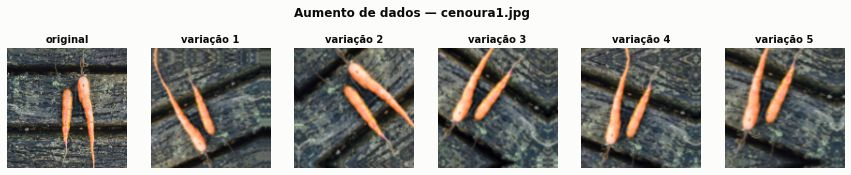

In [18]:
# Mostra cinco variações geradas pelo aumento de dados para uma imagem de treino.
camada_aumento = criar_cnn(SEED).get_layer("aumento_de_dados")
exemplo = keras.ops.convert_to_tensor(np.repeat(x_treino[:1], 5, axis=0))
variacoes = keras.ops.convert_to_numpy(camada_aumento(exemplo, training=True))

fig, eixos = plt.subplots(1, 6, figsize=(15, 2.9))
for eixo, imagem, titulo in zip(
    eixos, [x_treino[0], *variacoes], ["original", *[f"variação {i}" for i in range(1, 6)]]
):
    eixo.imshow(np.clip(imagem, 0, 255).astype("uint8"))
    eixo.set_title(titulo, fontsize=10)
    eixo.axis("off")
fig.suptitle(f"Aumento de dados — {treino.loc[0, 'arquivo']}", fontsize=12, fontweight="bold")
mostrar_foto(fig)

In [19]:
def treinar_cnn(semente):
    """Treina uma CNN com a semente informada; devolve o modelo, o histórico, o tempo e a melhor época."""
    modelo = criar_cnn(semente)
    # A parada antecipada só passa a monitorar após a época 10, para que a oscilação inicial
    # da validação (8 imagens) não encerre o treino antes de a rede aprender.
    parada = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True, start_from_epoch=10
    )
    inicio = time.perf_counter()
    historico = modelo.fit(
        x_treino, y_treino,
        validation_data=(x_val, y_val),
        epochs=100,
        batch_size=16,
        callbacks=[parada],
        verbose=0,
    )
    duracao = time.perf_counter() - inicio
    return modelo, historico.history, duracao, parada.best_epoch + 1


# Treina o modelo principal com a semente do projeto.
cnn, historico, tempo_treino_cnn, melhor_epoca = treinar_cnn(SEED)
epocas_cnn = len(historico["loss"])
print(f"Treino concluído em {tempo_treino_cnn:.1f} s: {epocas_cnn} épocas, pesos restaurados da época {melhor_epoca}.")

Treino concluído em 26.6 s: 42 épocas, pesos restaurados da época 22.


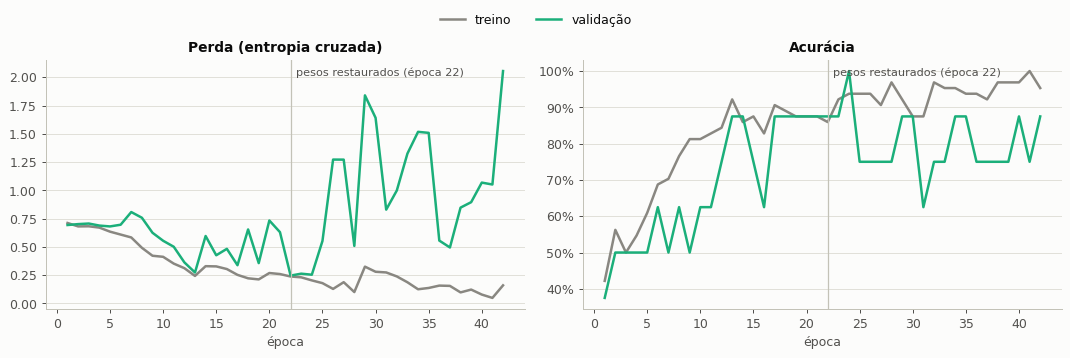

In [20]:
# Curvas de aprendizado: treino em cinza e validação na cor da CNN.
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
epocas = np.arange(1, epocas_cnn + 1)
for eixo, metrica, titulo in zip(eixos, ["loss", "accuracy"], ["Perda (entropia cruzada)", "Acurácia"]):
    eixo.plot(epocas, historico[metrica], color=NEUTRO, label="treino")
    eixo.plot(epocas, historico[f"val_{metrica}"], color=CORES["CNN do zero"], label="validação")
    # Linha vertical na época cujos pesos foram restaurados pela parada antecipada.
    eixo.axvline(melhor_epoca, color=EIXO, linewidth=1)
    eixo.annotate(
        f"pesos restaurados (época {melhor_epoca})", xy=(melhor_epoca, 0.97), xycoords=("data", "axes fraction"),
        xytext=(4, 0), textcoords="offset points", fontsize=9, color=TINTA_SECUNDARIA, va="top",
    )
    eixo.set_title(titulo)
    eixo.set_xlabel("época")
    eixo.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    eixo.grid(axis="y")
eixos[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{valor:.0%}"))
fig.legend(*eixos[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93))
mostrar_grafico(fig, "c_cnn_curvas_aprendizado.png")

In [21]:
# Probabilidades previstas pela CNN para as imagens de validação e de teste.
acuracia_val_cnn = float((cnn.predict(x_val, verbose=0).argmax(axis=1) == y_val).mean())
probabilidades = cnn.predict(x_teste, verbose=0)

tabela_cnn = pd.DataFrame({
    "arquivo": teste["arquivo"],
    "real": teste["classe"],
    "previsto": [CLASSES[indice] for indice in probabilidades.argmax(axis=1)],
    "P(tomate)": probabilidades[:, 0],
    "P(cenoura)": probabilidades[:, 1],
})
tabela_cnn["acertou a classe"] = tabela_cnn["real"] == tabela_cnn["previsto"]

print(f"Acurácia na validação: {acuracia_val_cnn:.1%}")
exibir(tabela_cnn, dec=["P(tomate)", "P(cenoura)"])
exibir_metricas(tabela_cnn)

Acurácia na validação: 87.5%


arquivo,real,previsto,P(tomate),P(cenoura),acertou a classe
cenoura33.jpg,cenoura,cenoura,0.051,0.949,sim
cenoura34.jpg,cenoura,cenoura,0.036,0.964,sim
cenoura35.jpg,cenoura,cenoura,0.272,0.728,sim
cenoura36.jpg,cenoura,cenoura,0.031,0.969,sim
tomate1.jpg,tomate,tomate,0.999,0.001,sim
tomate2.jpg,tomate,tomate,0.996,0.004,sim
tomate3.jpg,tomate,cenoura,0.237,0.763,não
tomate4.jpg,tomate,tomate,0.948,0.052,sim


acertos,acurácia,IC95% inferior,IC95% superior,F1 macro,precisão tomate,recall tomate,precisão cenoura,recall cenoura
7/8,87.5%,52.9%,97.8%,87.3%,100.0%,75.0%,80.0%,100.0%


### 6.1 Onde a CNN "olha"? (Grad-CAM)

O Grad-CAM destaca as regiões da imagem que mais contribuíram para a classe prevista. Ele mostra se a
rede usa o objeto ou se depende do fundo, o que um número de acurácia sozinho não revela.

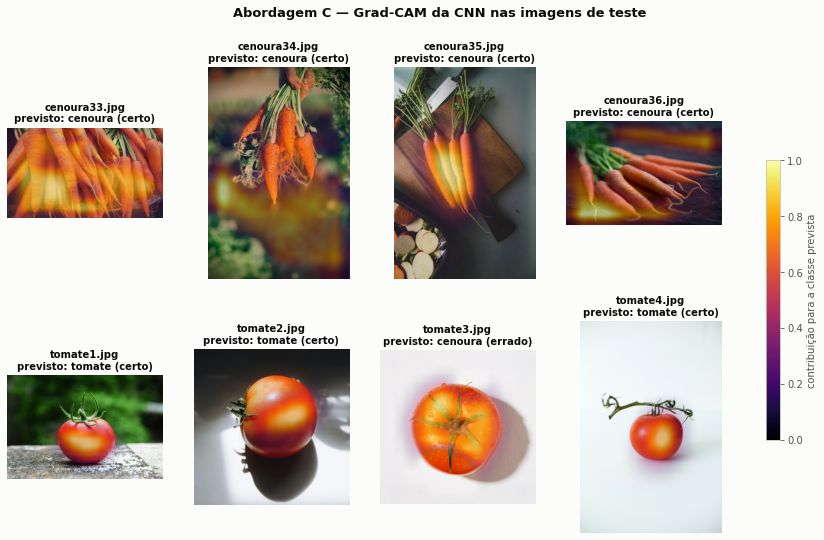

In [22]:
# Modelo auxiliar que devolve o último mapa convolucional e as probabilidades.
modelo_cam = keras.Model(cnn.inputs, [cnn.get_layer("mapa_final").output, cnn.output])


def grad_cam(x):
    """Mapa Grad-CAM (backend PyTorch) da classe prevista para uma imagem já redimensionada."""
    mapas, probabilidades_cam = modelo_cam(keras.ops.convert_to_tensor(x[None]), training=False)
    classe = int(probabilidades_cam[0].argmax())
    # Gradiente da probabilidade da classe prevista em relação a cada mapa de ativação.
    gradientes = torch.autograd.grad(probabilidades_cam[0, classe], mapas)[0]
    pesos = gradientes.mean(dim=(1, 2), keepdim=True)  # Importância média de cada canal.
    mapa = torch.relu((pesos * mapas).sum(dim=-1))[0]
    mapa = mapa / (mapa.max() + 1e-8)
    return mapa.detach().cpu().numpy(), CLASSES[classe]


fig, eixos = plt.subplots(2, 4, figsize=(16, 8.4))
for eixo, item, x in zip(eixos.flat, teste.itertuples(), x_teste):
    mapa, classe_prevista = grad_cam(x)
    altura, largura = item.imagem.shape[:2]
    mapa = np.clip(cv2.resize(mapa, (largura, altura), interpolation=cv2.INTER_CUBIC), 0, 1)
    # Sobreposição com transparência proporcional à importância: regiões irrelevantes ficam intactas.
    sobreposicao = plt.cm.inferno(mapa)
    sobreposicao[..., 3] = mapa * 0.7
    eixo.imshow(item.imagem)
    eixo.imshow(sobreposicao)
    resultado = "certo" if classe_prevista == item.classe else "errado"
    eixo.set_title(f"{item.arquivo}\nprevisto: {classe_prevista} ({resultado})", fontsize=10)
    eixo.axis("off")
fig.suptitle("Abordagem C — Grad-CAM da CNN nas imagens de teste", fontsize=13, fontweight="bold")
fig.colorbar(
    plt.cm.ScalarMappable(cmap="inferno", norm=plt.Normalize(0, 1)),
    ax=eixos, shrink=0.6, label="contribuição para a classe prevista",
)
mostrar_foto(fig, "c_cnn_grad_cam.jpg")

### 6.2 Robustez: o resultado depende da semente?

Com tão poucos dados, o resultado de uma única execução pode ser sorte ou azar. Por isso, repetimos o
treino com cinco sementes diferentes e reportamos a média e o desvio-padrão. O modelo principal, analisado
acima, é o da semente 42.

In [23]:
SEMENTES = [SEED, 7, 123, 2024, 31337]
robustez = [{
    "semente": SEED,
    "épocas": epocas_cnn,
    "melhor época": melhor_epoca,
    "tempo de treino (s)": tempo_treino_cnn,
    "acurácia validação": acuracia_val_cnn,
    "acurácia teste": float(tabela_cnn["acertou a classe"].mean()),
}]

for semente in SEMENTES[1:]:
    # Treina uma nova CNN do zero e avalia na validação e no teste.
    modelo, hist, duracao, melhor = treinar_cnn(semente)
    robustez.append({
        "semente": semente,
        "épocas": len(hist["loss"]),
        "melhor época": melhor,
        "tempo de treino (s)": duracao,
        "acurácia validação": float((modelo.predict(x_val, verbose=0).argmax(axis=1) == y_val).mean()),
        "acurácia teste": float((modelo.predict(x_teste, verbose=0).argmax(axis=1) == y_teste).mean()),
    })
    del modelo  # Libera a memória antes do próximo treino.

robustez = pd.DataFrame(robustez)
exibir(robustez, pct=["acurácia validação", "acurácia teste"], dec1=["tempo de treino (s)"])
print(
    f"Acurácia no teste: {robustez['acurácia teste'].mean():.1%} ± {robustez['acurácia teste'].std():.1%} | "
    f"tempo de treino: {robustez['tempo de treino (s)'].mean():.1f} ± {robustez['tempo de treino (s)'].std():.1f} s"
)

semente,épocas,melhor época,tempo de treino (s),acurácia validação,acurácia teste
42,42,22,26.6,87.5%,87.5%
7,48,28,28.4,100.0%,87.5%
123,49,29,29.4,62.5%,87.5%
2024,38,18,24.6,100.0%,87.5%
31337,44,24,26.8,100.0%,87.5%


Acurácia no teste: 87.5% ± 0.0% | tempo de treino: 27.2 ± 1.8 s


In [24]:
# Salva o modelo principal no Drive (formato nativo do Keras), usado depois no teste de tempo em CPU.
caminho_cnn = output_path / "cnn_do_zero.keras"
cnn.save(caminho_cnn)

# O .keras inclui o estado do otimizador Adam, e os .pt das YOLOs não incluem.
# Para comparar tamanhos de forma justa, salvamos também somente os pesos (float32).
caminho_pesos_cnn = output_path / "cnn_do_zero_pesos.npz"
np.savez(caminho_pesos_cnn, *cnn.get_weights())
print(f"Modelo completo: {caminho_cnn.name} ({caminho_cnn.stat().st_size / 1e6:.2f} MB, com o estado do otimizador)")
print(f"Somente os pesos: {caminho_pesos_cnn.name} ({caminho_pesos_cnn.stat().st_size / 1e6:.2f} MB)")

Modelo completo: cnn_do_zero.keras (2.96 MB, com o estado do otimizador)
Somente os pesos: cnn_do_zero_pesos.npz (0.97 MB)


### Análise da abordagem C

- **Acerto:**
  - O modelo principal acertou **7 de 8** imagens de teste (87,5%; IC95% de 53% a 98%).
  - O único erro foi o `tomate3`, classificado como cenoura com probabilidade de 0,76.
  - É o tomate mais alaranjado do teste, o mesmo que confundiu a YOLO tradicional. A cor é uma pista
    forte para a rede, e nesse caso ela engana. O Grad-CAM mostra a rede olhando justamente a parte
    superior do fruto, a mais alaranjada.
- **Grad-CAM:** nas demais imagens, a rede se concentra nos objetos (raízes e frutos), e não no fundo. É um
  bom sinal de que aprendeu características relevantes, mesmo com 64 imagens.
- **Curvas de aprendizado:**
  - A perda de treino cai de forma contínua.
  - A de validação oscila muito, porque cada uma das 8 imagens vale 12,5 pontos.
  - Os pesos restaurados (época 22) coincidem com o ponto de menor perda de validação, antes de a rede
    começar a sobreajustar.
- **Robustez:**
  - As cinco sementes acertaram 7 de 8 no teste (87,5% ± 0,0%).
  - A acurácia na validação, porém, variou de 62,5% a 100%.
  - O resultado no teste foi estável, mas a validação de 8 imagens é um termômetro ruidoso para escolher
    a época de parada.
- **Tempo de treino:** cerca de **27 segundos** na GPU T4, contra 74 minutos da YOLO na Entrega 1. As razões:
  - as imagens já estão reduzidas a 128 px em memória, enquanto a YOLO decodificou fotos de até 45 MP do
    Drive a cada época;
  - a rede é cerca de 29 vezes menor (0,24 milhão contra 7 milhões de parâmetros).

## 7. Tempo de inferência

Medimos o tempo **por imagem**, uma de cada vez, simulando uma câmera que envia fotos para o modelo:

- **Ponto de partida:** a imagem já carregada em memória. A leitura do arquivo fica de fora, pois é igual
  para todas as abordagens.
- **YOLOs:** inclui o redimensionamento (*letterbox*), a rede e o NMS, com confiança ≥ 0,25.
- **CNN:** inclui o redimensionamento e a rede.
- **Procedimento:** cada modelo recebe uma rodada de aquecimento com as 8 imagens. Depois medimos 20
  rodadas na GPU e 5 na CPU.
- **Sincronização:** na GPU, esperamos o fim do processamento antes de parar o cronômetro.

Medimos na **GPU** e na **CPU** do Colab. A CPU representa clientes sem placa de vídeo, como computadores
simples na fazenda ou dispositivos de borda.

In [25]:
def medir_latencia(prever, imagens, rodadas, sincronizar=None):
    """Tempo de inferência por imagem (ms), após uma rodada de aquecimento."""
    for imagem in imagens:  # Aquecimento: a primeira chamada inclui custos de inicialização.
        prever(imagem)
    if sincronizar:
        sincronizar()
    tempos = []
    for _ in range(rodadas):
        for imagem in imagens:
            inicio = time.perf_counter()
            prever(imagem)
            if sincronizar:
                sincronizar()  # Espera a GPU terminar antes de parar o cronômetro.
            tempos.append((time.perf_counter() - inicio) * 1000)
    return np.array(tempos)


def carregar_yolo_cpu(caminho_pesos):
    """Carrega uma cópia da YOLO na CPU, com os mesmos limiares da avaliação."""
    modelo = torch.hub.load(
        str(yolo_path), "custom", path=str(caminho_pesos), source="local", device="cpu", _verbose=False
    )
    modelo.conf, modelo.iou = CONF_THRES, IOU_NMS
    return modelo


# Usa os limiares da avaliação para medir o tempo das YOLOs.
for modelo in (modelo_custom, modelo_coco):
    modelo.conf, modelo.iou = CONF_THRES, IOU_NMS

imagens_teste = teste["imagem"].tolist()
dispositivos = ["cuda", "cpu"] if DEVICE == "cuda" else ["cpu"]
medicoes = []

for dispositivo in dispositivos:
    na_gpu = dispositivo == "cuda"
    rodadas = 20 if na_gpu else 5
    sincronizar = torch.cuda.synchronize if na_gpu else None

    # Na GPU, usa os modelos já carregados; na CPU, carrega cópias quando o padrão for a GPU.
    if dispositivo == DEVICE:
        yolo_a, yolo_b, cnn_dispositivo = modelo_custom, modelo_coco, cnn
    else:
        yolo_a, yolo_b = carregar_yolo_cpu(best_pt_path), carregar_yolo_cpu(pesos_coco)
        with keras.device("cpu"):
            cnn_dispositivo = keras.models.load_model(caminho_cnn)

    def prever_cnn(imagem, modelo=cnn_dispositivo, dispositivo=dispositivo):
        with keras.device(dispositivo):
            return modelo.predict_on_batch(preparar_cnn(imagem)[None])

    candidatos = {
        "YOLO customizada": lambda imagem, modelo=yolo_a: modelo(imagem, size=IMG_YOLO),
        "YOLO tradicional": lambda imagem, modelo=yolo_b: modelo(imagem, size=IMG_YOLO),
        "CNN do zero": prever_cnn,
    }
    for nome, prever in candidatos.items():
        tempos = medir_latencia(prever, imagens_teste, rodadas, sincronizar if nome != "CNN do zero" else None)
        medicoes.append({
            "abordagem": nome,
            "dispositivo": "GPU" if na_gpu else "CPU",
            "média (ms)": tempos.mean(),
            "desvio (ms)": tempos.std(),
            "mediana (ms)": np.median(tempos),
            "p95 (ms)": np.percentile(tempos, 95),
            "imagens/s": 1000 / tempos.mean(),
        })

latencias = pd.DataFrame(medicoes)
exibir(latencias, dec1=["média (ms)", "desvio (ms)", "mediana (ms)", "p95 (ms)", "imagens/s"])

abordagem,dispositivo,média (ms),desvio (ms),mediana (ms),p95 (ms),imagens/s
YOLO customizada,GPU,11.6,2.1,11.1,16.3,86.2
YOLO tradicional,GPU,11.8,1.5,11.3,13.8,84.7
CNN do zero,GPU,15.8,2.3,15.5,19.5,63.3
YOLO customizada,CPU,418.9,186.6,361.8,759.1,2.4
YOLO tradicional,CPU,222.2,38.8,203.0,286.9,4.5
CNN do zero,CPU,23.7,2.8,22.9,30.2,42.2


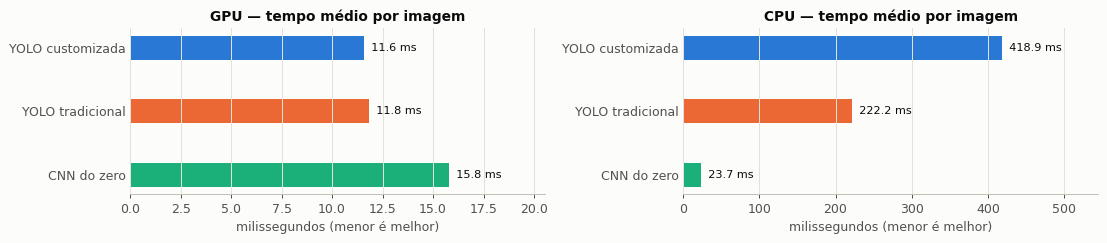

In [26]:
# Tempo médio por imagem, com um painel por dispositivo (escalas independentes).
paineis = latencias["dispositivo"].unique()
fig, eixos = plt.subplots(1, len(paineis), figsize=(6.2 * len(paineis), 2.8), squeeze=False)
for eixo, dispositivo in zip(eixos.flat, paineis):
    parte = latencias[latencias["dispositivo"] == dispositivo].iloc[::-1]
    eixo.barh(parte["abordagem"], parte["média (ms)"], height=0.38, color=[CORES[nome] for nome in parte["abordagem"]])
    for posicao, valor in enumerate(parte["média (ms)"]):
        eixo.text(valor, posicao, f"  {valor:.1f} ms", va="center", fontsize=9, color=TINTA)
    eixo.set_xlim(0, parte["média (ms)"].max() * 1.3)
    eixo.set_title(f"{dispositivo} — tempo médio por imagem")
    eixo.set_xlabel("milissegundos (menor é melhor)")
    eixo.grid(axis="x")
    eixo.spines["left"].set_visible(False)
    eixo.tick_params(axis="y", length=0)
fig.tight_layout()
mostrar_grafico(fig, "tempo_inferencia.png")

### Análise do tempo de inferência

- **Na GPU, todas ficam entre 12 e 16 ms por imagem.**
  - As YOLOs levam cerca de 12 ms, e a CNN, cerca de 16 ms.
  - A CNN é muito menor, mas o custo fixo de cada chamada do Keras (preparar a entrada e copiar para a GPU)
    pesa mais que o cálculo da rede. Com uma imagem por vez, a GPU fica subutilizada.
  - Na prática, a diferença na GPU não é decisiva.
- **Na CPU, a CNN é muito mais rápida: cerca de 24 ms**, contra 222 a 419 ms das YOLOs (9 a 18 vezes
  menos). Ela tem 29 vezes menos parâmetros e trabalha com imagens de 128 px, contra 640 px das YOLOs.
- **As duas YOLOs têm o mesmo custo real.**
  - É a mesma arquitetura YOLOv5s; só a última camada muda (2 classes contra 80).
  - A diferença na CPU (419 × 222 ms) vem da variação da máquina do Colab, que tem apenas 2 núcleos
    compartilhados. A YOLO customizada, medida primeiro, teve desvio de 187 ms e p95 de 759 ms.
- **Na prática, para um cliente sem GPU:**
  - as YOLOs processam de 2 a 4 imagens por segundo, o suficiente para fotos periódicas da lavoura, mas
    não para vídeo em tempo real;
  - a CNN processa cerca de 40 imagens por segundo.

## 8. Comparativo final

Reunimos os quatro critérios do enunciado em duas tabelas:

- **precisão** no teste, com todas as variantes avaliadas;
- **custo**, com o treino ou a customização, o tamanho do modelo e o tempo de inferência.

A facilidade de uso é discutida na seção 8.1. O resultado **oficial** das YOLOs usa o limiar de 0,25;
as linhas "calibrado" usam o limiar escolhido na validação (seção 5.3).

In [27]:
def resumo_precisao(nome, limiar, tabela):
    """Linha da tabela de precisão: acertos, acurácia com IC95%, F1, recall por classe e localização."""
    m = metricas_classificacao(tabela["real"], tabela["previsto"])
    return {
        "abordagem": nome,
        "limiar": limiar,
        "acertos": m["acertos"],
        "acurácia (IC95%)": f"{m['acurácia']:.0%} ({m['IC95% inferior']:.0%}–{m['IC95% superior']:.0%})",
        "F1 macro": m["F1 macro"],
        "recall tomate": m["recall tomate"],
        "recall cenoura": m["recall cenoura"],
        "objeto localizado": tabela["localizou"].mean() if "localizou" in tabela else np.nan,
    }


limiar_a, tabela_custom_calibrada = calibrado["A. YOLO customizada"]
limiar_b, tabela_coco_calibrada = calibrado["B. YOLO tradicional (mapeada)"]

precisao = pd.DataFrame([
    resumo_precisao("A. YOLO customizada", "0.25 (oficial)", tabela_custom),
    resumo_precisao("A. YOLO customizada", f"{limiar_a:.2f} (calibrado)", tabela_custom_calibrada),
    resumo_precisao("B. YOLO tradicional — estrito", "0.25 (oficial)", tabela_coco_estrito),
    resumo_precisao("B. YOLO tradicional — mapeada", "0.25 (oficial)", tabela_coco_mapa),
    resumo_precisao("B. YOLO tradicional — mapeada", f"{limiar_b:.2f} (calibrado)", tabela_coco_calibrada),
    resumo_precisao("C. CNN do zero (semente 42)", "—", tabela_cnn),
])
print("Precisão nas 8 imagens de teste:")
exibir(precisao, pct=["F1 macro", "recall tomate", "recall cenoura", "objeto localizado"])
print(
    f"CNN do zero em 5 sementes: acurácia no teste de {robustez['acurácia teste'].mean():.1%} "
    f"± {robustez['acurácia teste'].std():.1%} (média ± desvio-padrão)."
)

Precisão nas 8 imagens de teste:


abordagem,limiar,acertos,acurácia (IC95%),F1 macro,recall tomate,recall cenoura,objeto localizado
A. YOLO customizada,0.25 (oficial),4/8,50% (22%–78%),50.0%,100.0%,0.0%,50.0%
A. YOLO customizada,0.10 (calibrado),8/8,100% (68%–100%),100.0%,100.0%,100.0%,87.5%
B. YOLO tradicional — estrito,0.25 (oficial),4/8,50% (22%–78%),44.4%,0.0%,100.0%,0.0%
B. YOLO tradicional — mapeada,0.25 (oficial),6/8,75% (41%–93%),77.8%,50.0%,100.0%,25.0%
B. YOLO tradicional — mapeada,0.25 (calibrado),6/8,75% (41%–93%),77.8%,50.0%,100.0%,25.0%
C. CNN do zero (semente 42),—,7/8,88% (53%–98%),87.3%,75.0%,100.0%,—


CNN do zero em 5 sementes: acurácia no teste de 87.5% ± 0.0% (média ± desvio-padrão).


In [28]:
def latencia(nome, dispositivo):
    """Tempo médio por imagem de uma abordagem em um dispositivo (ms), se medido."""
    linha = latencias[(latencias["abordagem"] == nome) & (latencias["dispositivo"] == dispositivo)]
    return f"{linha['média (ms)'].iloc[0]:.1f} ms" if len(linha) else "não medido"


# Número de parâmetros e tamanho dos pesos em disco (sem o estado do otimizador).
parametros = {
    "YOLO customizada": sum(p.numel() for p in modelo_custom.parameters()),
    "YOLO tradicional": sum(p.numel() for p in modelo_coco.parameters()),
    "CNN do zero": cnn.count_params(),
}
tamanhos = {
    "YOLO customizada": best_pt_path.stat().st_size / 1e6,
    "YOLO tradicional": pesos_coco.stat().st_size / 1e6,
    "CNN do zero": caminho_pesos_cnn.stat().st_size / 1e6,
}
texto_treino = {
    "YOLO customizada": f"{TEMPO_TREINO_E1_MIN[60]:.1f} min (60 épocas, Entrega 1)",
    "YOLO tradicional": f"sem treino; {tempo_mapeamento:.1f} s de mapeamento",
    "CNN do zero": f"{tempo_treino_cnn:.1f} s ({epocas_cnn} épocas; média de 5 sementes: "
                   f"{robustez['tempo de treino (s)'].mean():.1f} s)",
}
rotulos = {
    "YOLO customizada": "caixa de cada objeto",
    "YOLO tradicional": "nenhum (classe da imagem só para o mapeamento)",
    "CNN do zero": "classe de cada imagem",
}

custo = pd.DataFrame([
    {
        "abordagem": nome,
        "rótulo exigido": rotulos[nome],
        "treino / customização": texto_treino[nome],
        "parâmetros": f"{parametros[nome] / 1e6:.2f} M",
        "pesos em disco": f"{tamanhos[nome]:.1f} MB",
        "inferência GPU": latencia(nome, "GPU"),
        "inferência CPU": latencia(nome, "CPU"),
    }
    for nome in CORES
])
print("Custo de cada abordagem:")
exibir(custo)

Custo de cada abordagem:


abordagem,rótulo exigido,treino / customização,parâmetros,pesos em disco,inferência GPU,inferência CPU
YOLO customizada,caixa de cada objeto,"74.3 min (60 épocas, Entrega 1)",7.02 M,14.4 MB,11.6 ms,418.9 ms
YOLO tradicional,nenhum (classe da imagem só para o mapeamento),sem treino; 1.1 s de mapeamento,7.23 M,14.8 MB,11.8 ms,222.2 ms
CNN do zero,classe de cada imagem,26.6 s (42 épocas; média de 5 sementes: 27.2 s),0.24 M,1.0 MB,15.8 ms,23.7 ms


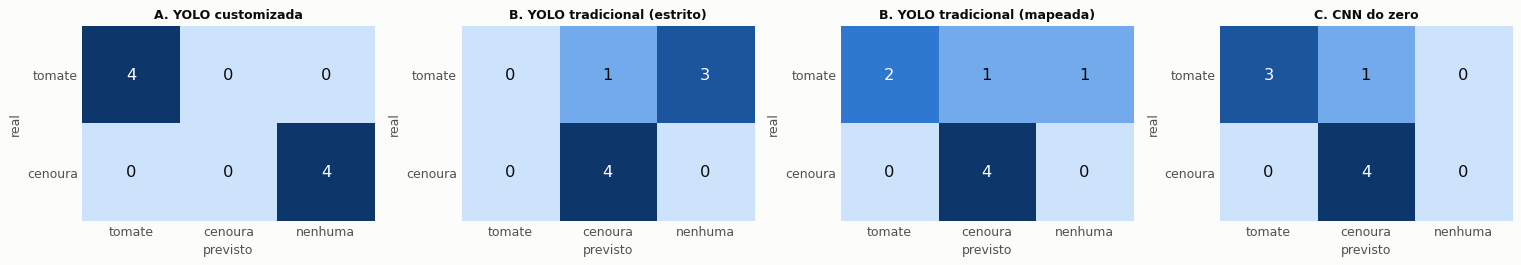

In [29]:
# Matrizes de confusão com o limiar oficial (linhas = classe real; colunas = resposta do modelo).
avaliacoes = {
    "A. YOLO customizada": tabela_custom,
    "B. YOLO tradicional (estrito)": tabela_coco_estrito,
    "B. YOLO tradicional (mapeada)": tabela_coco_mapa,
    "C. CNN do zero": tabela_cnn,
}
fig, eixos = plt.subplots(1, 4, figsize=(17, 3.6))
for eixo, (nome, tabela) in zip(eixos, avaliacoes.items()):
    matriz = confusion_matrix(tabela["real"], tabela["previsto"], labels=ROTULOS_MATRIZ)[:2]
    eixo.imshow(matriz, cmap=CMAP_AZUL, vmin=0, vmax=4)
    for (linha, coluna), valor in np.ndenumerate(matriz):
        eixo.text(coluna, linha, valor, ha="center", va="center", fontsize=13,
                  color="white" if valor >= 2 else TINTA)
    eixo.set_xticks(range(3), ROTULOS_MATRIZ)
    eixo.set_yticks(range(2), CLASSES)
    eixo.set_xlabel("previsto")
    eixo.set_ylabel("real")
    eixo.set_title(nome, fontsize=10)
    eixo.spines[:].set_visible(False)
    eixo.tick_params(length=0)
fig.tight_layout()
mostrar_grafico(fig, "matrizes_confusao.png")

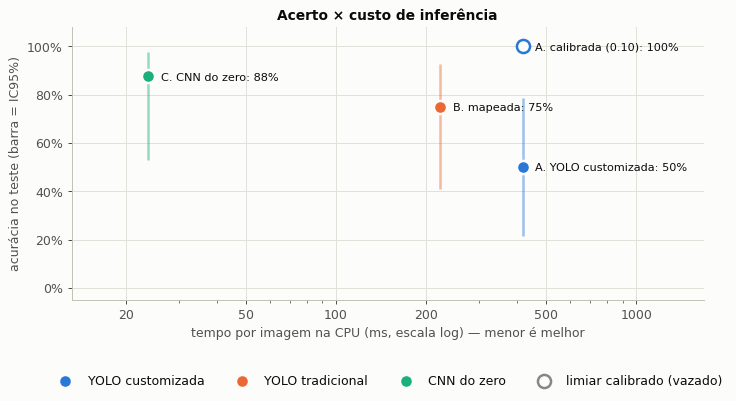

In [30]:
# Equilíbrio entre acerto e custo: acurácia no teste (com IC95%) × tempo por imagem na CPU.
# Marcador cheio = limiar oficial (0,25); marcador vazado = limiar calibrado na validação.
pontos = [
    ("YOLO customizada", "A. YOLO customizada", tabela_custom, True),
    ("YOLO tradicional", "B. mapeada", tabela_coco_mapa, True),
    ("CNN do zero", "C. CNN do zero", tabela_cnn, True),
]
# Pontos calibrados entram só quando o limiar escolhido difere do oficial.
if limiar_a != CONF_THRES:
    pontos.append(("YOLO customizada", f"A. calibrada ({limiar_a:.2f})", tabela_custom_calibrada, False))
if limiar_b != CONF_THRES:
    pontos.append(("YOLO tradicional", f"B. calibrada ({limiar_b:.2f})", tabela_coco_calibrada, False))
fig, eixo = plt.subplots(figsize=(8.5, 4.8))
x_valores = []
for nome, rotulo, tabela, oficial in pontos:
    m = metricas_classificacao(tabela["real"], tabela["previsto"])
    x = latencias[(latencias["abordagem"] == nome) & (latencias["dispositivo"] == "CPU")]["média (ms)"].iloc[0]
    x_valores.append(x)
    if oficial:
        eixo.vlines(x, m["IC95% inferior"], m["IC95% superior"], color=CORES[nome], linewidth=2, alpha=0.45)
    eixo.scatter(
        x, m["acurácia"], s=110, zorder=3, linewidth=2,
        color=CORES[nome] if oficial else SUPERFICIE, edgecolor=SUPERFICIE if oficial else CORES[nome],
        label=nome if oficial else None,
    )
    eixo.annotate(f"{rotulo}: {m['acurácia']:.0%}", (x, m["acurácia"]), xytext=(10, -3),
                  textcoords="offset points", fontsize=9, color=TINTA)

# Eixo X em escala log, com rótulos simples em milissegundos.
eixo.set_xscale("log")
eixo.set_xlim(min(x_valores) / 1.8, max(x_valores) * 4)
marcas = [m for m in (1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000) if eixo.get_xlim()[0] <= m <= eixo.get_xlim()[1]]
eixo.set_xticks(marcas, [f"{m:g}" for m in marcas])
eixo.xaxis.set_minor_formatter(plt.NullFormatter())
eixo.set_ylim(-0.05, 1.08)
eixo.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{valor:.0%}"))
eixo.set_xlabel("tempo por imagem na CPU (ms, escala log) — menor é melhor")
eixo.set_ylabel("acurácia no teste (barra = IC95%)")
eixo.set_title("Acerto × custo de inferência")
eixo.grid(True)
# Entrada extra da legenda explicando o marcador vazado.
eixo.scatter([], [], s=110, color=SUPERFICIE, edgecolor=NEUTRO, linewidth=2, label="limiar calibrado (vazado)")
eixo.legend(loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.36))
fig.tight_layout()
mostrar_grafico(fig, "acerto_x_custo.png")

### 8.1 Facilidade de uso e integração

| Aspecto | A. YOLO customizada | B. YOLO tradicional | C. CNN do zero |
| --- | --- | --- | --- |
| **Preparação dos dados** | Desenhar o contorno de cada objeto (Make Sense IA) e converter para caixas YOLO | Nenhuma; a classe da imagem só é necessária para o mapeamento opcional | Só a classe de cada imagem (o nome do arquivo bastou) |
| **Treino** | Pronto no `train.py`: um comando com hiperparâmetros padrão, mas lento com fotos grandes | Não há | Arquitetura, aumento de dados e laço de treino definidos por nós, com mais decisões e mais risco (ex.: BatchNorm) |
| **Inferência** | Duas linhas: `torch.hub.load` e chamada com a imagem | Duas linhas, idênticas às da A | Redimensionar e chamar `predict` |
| **O que entrega** | Classe, caixa e confiança de cada objeto: permite contar e localizar | Caixa e uma das 80 classes do COCO, sem tomate | Só a classe da imagem: não localiza nem conta |
| **Incluir uma nova classe** | Rotular caixas e re-treinar | Impossível sem re-treino (vocabulário fechado) | Rotular imagens e re-treinar |
| **Implantação** | `export.py` gera ONNX, TensorRT, TFLite etc.; cerca de 14 MB | Igual à A | Modelo de cerca de 1 MB, leve para computadores simples |

**Síntese:**

- **YOLO tradicional:** é a mais fácil para começar, mas só serve se as classes já existirem no COCO.
- **YOLO customizada:** concentra o esforço na rotulação; o treino e a inferência são padronizados.
- **CNN do zero:** exige mais conhecimento de projeto (arquitetura e regularização), mas é a mais simples de
  rotular e a mais leve para implantar.

## 9. Conclusões

### Principais achados

1. **Não há uma abordagem melhor em tudo; a escolha depende da pergunta do cliente.**
   - *"Onde estão e quantos são?"* Só as YOLOs respondem. A customizada, com o limiar calibrado na
     validação, acertou as 8 imagens e localizou 7.
   - *"O que tem nesta foto?"* A CNN do zero acertou 7 de 8 em todas as sementes, treina em cerca de
     30 segundos e é de 9 a 18 vezes mais rápida na CPU.
   - *"Preciso de algo hoje, sem rotular nada"*: a YOLO tradicional resolve só se as classes existirem no
     COCO. Funciona para cenoura, mas não para tomate.
2. **A customização compensa, mas precisa de calibração.**
   - A e B têm a mesma arquitetura e os mesmos pesos iniciais; a diferença entre elas é a customização.
   - A customização ensinou o conceito de "tomate", que o COCO não tem.
   - O limiar herdado (0,25) escondeu as cenouras, que a rede encontrava com confiança mais baixa.
3. **A qualidade da rotulação pesou mais que a arquitetura.** A marcação de uma caixa por foto, inconsistente
   nas cenouras, explica a baixa confiança da YOLO customizada nessa classe. Também explica a baixa
   localização da YOLO tradicional, que acerta as cenouras mas desenha caixas diferentes das nossas.
4. **O `tomate3` foi difícil para B e C.** Sob aquela iluminação, o tomate é alaranjado. Modelos que dependem
   muito da cor erram nesse tipo de caso.

### Pontos fortes do trabalho

- Mesma base, mesmo conjunto de teste e o mesmo protocolo de avaliação para as três abordagens.
- Decisões tomadas sem olhar o teste: o mapeamento de classes foi definido no treino; o limiar e a parada
  antecipada, na validação.
- Incerteza explícita, com intervalos de confiança de 95% e a CNN repetida com cinco sementes.
- Interpretação visual com as grades de detecção e o Grad-CAM.
- Tempos de inferência medidos no mesmo hardware, com aquecimento e sincronização da GPU.

### Limitações

- **Teste com 8 imagens:** os intervalos de confiança se sobrepõem, então as diferenças de acurácia entre as
  abordagens **não são estatisticamente conclusivas**.
- **Rotulação herdada da Entrega 1:** uma caixa por imagem, com padrões diferentes para as cenouras. A métrica
  de localização penaliza detecções corretas de objetos não marcados.
- **Tempo de treino da YOLO:** foi medido na Entrega 1 e inclui a leitura do Drive e a decodificação de fotos
  de até 45 MP. Não mede só o custo da rede.
- **CNN:** não localiza objetos. Em uma foto com tomate e cenoura juntos, daria uma única resposta.
- **Imagens da internet:** a maioria tem fundo limpo e objeto centralizado, bem diferente de câmeras
  na lavoura.
- **Variação entre execuções:** o treino da CNN depende da semente e do não determinismo da GPU. Em uma
  execução preliminar em CPU, ainda com uma versão anterior do critério de parada, duas das cinco sementes
  acertaram 6 de 8 em vez de 7.
- **Medição de tempo:** a CPU do Colab é compartilhada, então os tempos em CPU variam entre execuções. As
  ordens de grandeza (cerca de 20 ms contra centenas de ms) são o resultado confiável.

### Recomendação para o cliente da FarmTech

- **Para localizar e contar** (por exemplo, estimar produção): YOLO customizada, com três melhorias:
  1. rotular **todos** os objetos de cada foto, com um padrão para cenouras (cada raiz, sem as folhas);
  2. ampliar a base com fotos reais da lavoura;
  3. calibrar o limiar na validação.

  A YOLO tradicional pode servir como **pré-anotadora**: ela já encontra cenouras e acelera a rotulação.
- **Para apenas classificar imagens** (por exemplo, triagem): CNN, que é leve, rápida em CPU e simples de
  rotular. Para mais robustez, o próximo passo é o *transfer learning* de uma rede pré-treinada, tema do
  "Ir Além".